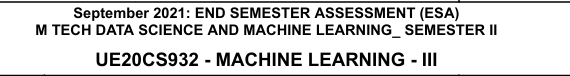

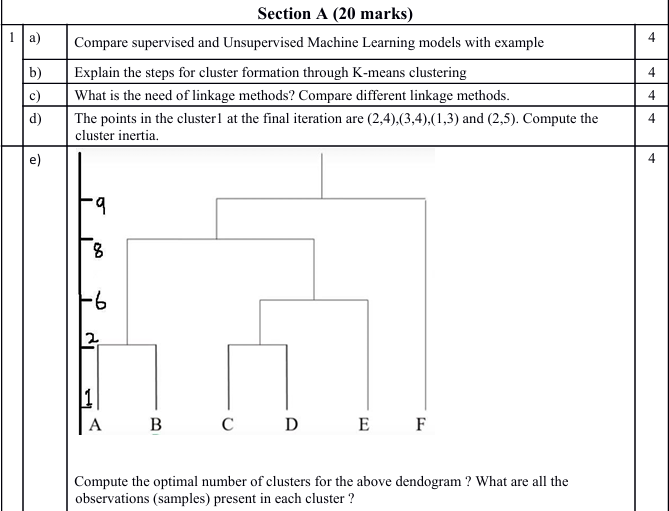/

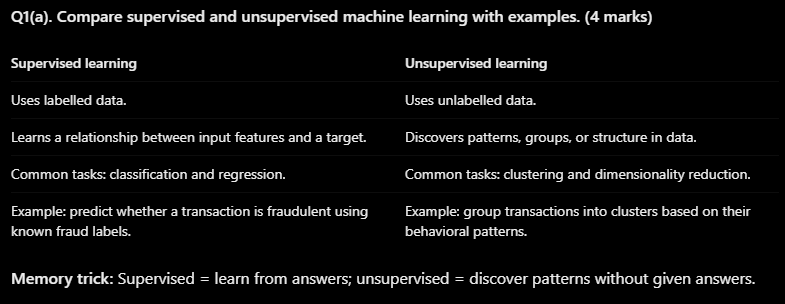  Also write algorithm names

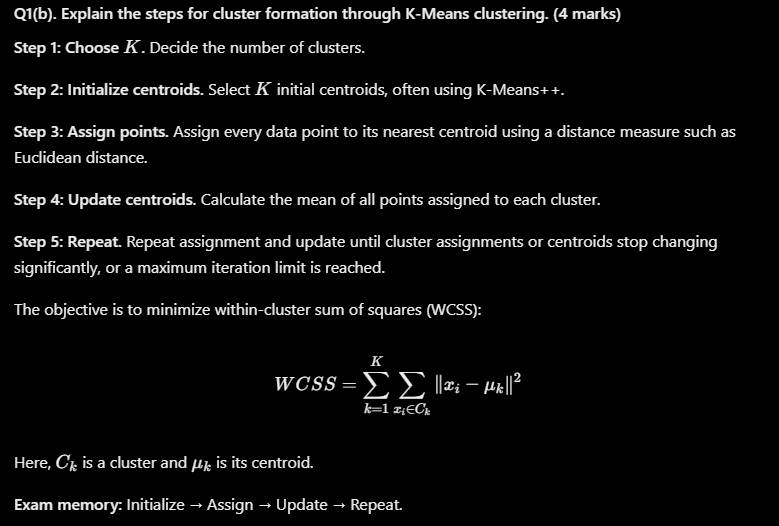

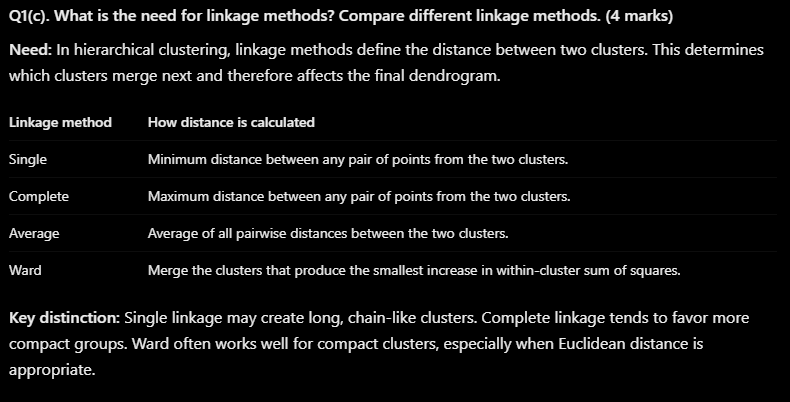

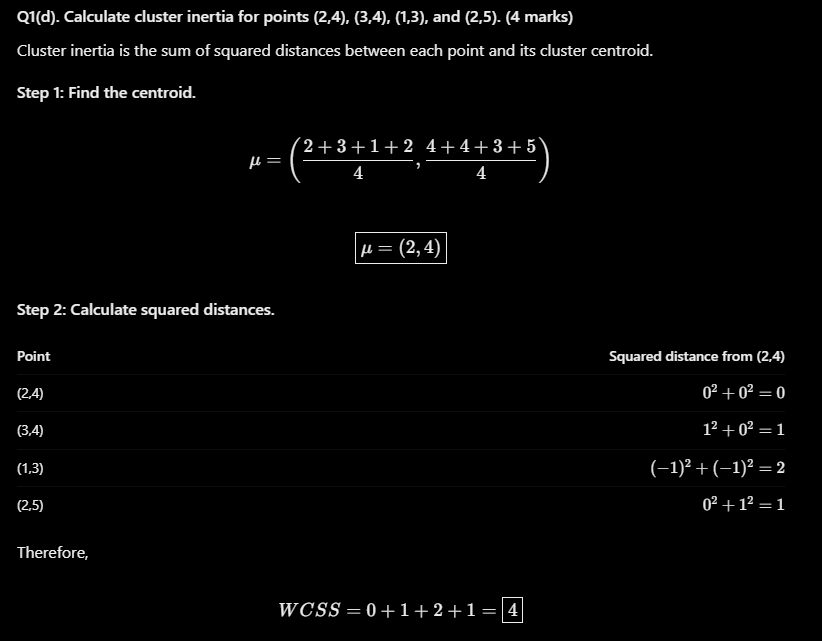

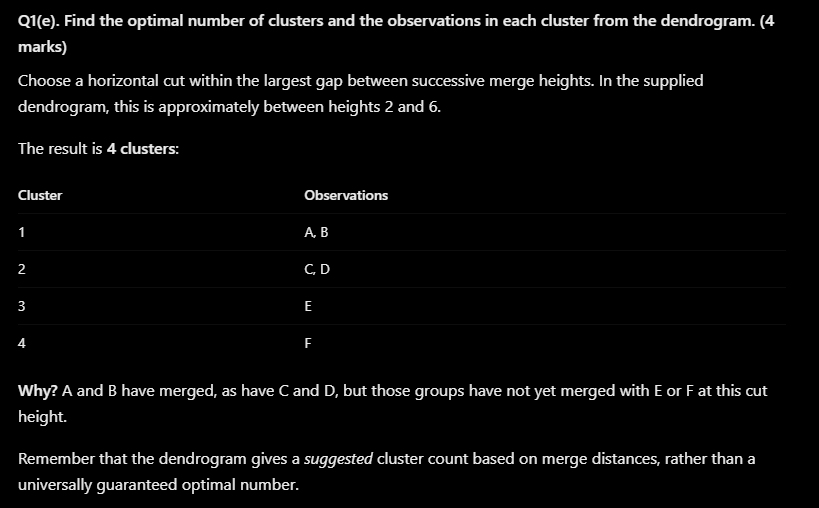

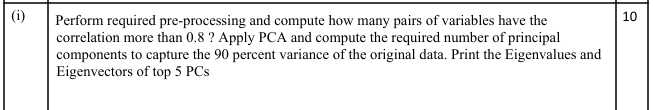

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

In [3]:
# Step 1 — Preprocess and count correlated pairs

#Load Data
df = pd.read_csv("cluster_data.csv")
print("Shape:",df.shape)

print("Missing:",df.isnull().sum().sum())

print("Duplicates:",df.duplicated().sum())

#if duplicates exist - drop them using df = df.drop_duplicates()

Shape: (10299, 563)
Missing: 0
Duplicates: 0


In [6]:
# Remove target and subject identifier for clustering
X = df.drop(columns=['Activity','subject/Participant'],errors="ignore")
# for dropping single column --> X = df.drop("column",axis=1)

# Handle missing values
X = X.fillna(X.median())

# Count pair correlation
corr = X.corr()
# if negative and positive side , use corr = X.corr().abs()

pairs = ((corr > 0.8).sum().sum() - len(corr)) // 2  # --> to avoid counting twice
print("Pairs with correlation GT 0.8:",pairs)

Pairs with correlation GT 0.8: 20672


In [7]:
# Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [8]:
# Step 2 — Apply PCA and print the required values

pca = PCA(n_components=0.90)
X_pca90 = pca.fit_transform(X_scaled)

print("Components for 90% variance:",pca.n_components_)
print("Top 5 Eigen values:",pca.explained_variance_[:5])
print("Top 5 Eigen vectors:",pca.components_[:5])

Components for 90% variance: 65
Top 5 Eigen values: [284.66906046  35.0052311   15.10675009  13.76194237  10.59795807]
Top 5 Eigen vectors: [[ 0.00032202 -0.00265502 -0.00183102 ... -0.02322551  0.028696
   0.02622314]
 [ 0.01667862  0.00050924 -0.00496277 ...  0.0248285  -0.04036438
  -0.02188039]
 [-0.03345162  0.00185358  0.00901579 ...  0.0927247  -0.06636139
  -0.04427153]
 [-0.02166831 -0.00044926  0.00950881 ...  0.13336415 -0.11143218
  -0.14892314]
 [-0.00083394 -0.00998015 -0.00324271 ...  0.16400778 -0.12754761
  -0.08514572]]


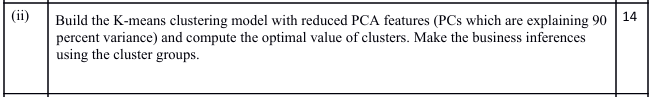

In [12]:
# Step 2 — Find a suitable K 

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

scores = []

for k in range(2,11):
    km = KMeans(n_clusters=k,random_state=42,n_init=10)
    labels = km.fit_predict(X_pca90)
    scores.append(silhouette_score(X_pca90,labels))

best_k = range(2,11)[np.argmax(scores)]
print("Best k:",best_k)

Best k: 2


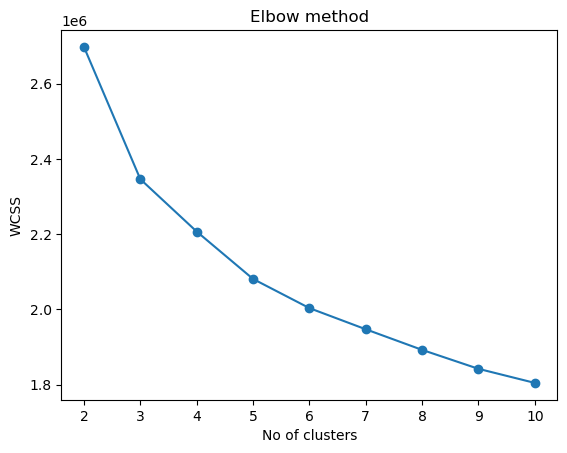

In [15]:
# Elbow plot
plt.plot(range(2,11),wcss,marker="o")
plt.xlabel("No of clusters")
plt.ylabel("WCSS")
plt.title("Elbow method")
plt.show()


How to interpret the plots:
- Elbow: look for the point after which adding more clusters reduces WCSS less substantially.
- Silhouette: a larger value usually indicates better separation and within-cluster cohesion.

In [ ]:
# Elbow plot gives 5 , but elbow method is subjective,
# Silhouette is highest at 2, hence k = 2

In [16]:
# Step 2: Fit final K-Means and inspect cluster characteristics.

km = KMeans(n_clusters=best_k, random_state=42, n_init=10)
labels = km.fit_predict(X_pca90)

# Compare original sensor features after clustering
cluster_data = X.copy()
cluster_data["Cluster"] = labels

print(cluster_data.groupby("Cluster").mean().round(2))

         tBodyAcc-mean()-X  tBodyAcc-mean()-Y  tBodyAcc-mean()-Z  \
Cluster                                                            
0                     0.28              -0.02              -0.11   
1                     0.27              -0.02              -0.11   

         tBodyAcc-std()-X  tBodyAcc-std()-Y  tBodyAcc-std()-Z  \
Cluster                                                         
0                   -0.98             -0.94             -0.94   
1                   -0.16              0.00             -0.22   

         tBodyAcc-mad()-X  tBodyAcc-mad()-Y  tBodyAcc-mad()-Z  \
Cluster                                                         
0                   -0.98             -0.94             -0.94   
1                   -0.22             -0.03             -0.22   

         tBodyAcc-max()-X  ...  fBodyBodyGyroJerkMag-meanFreq()  \
Cluster                    ...                                    
0                   -0.92  ...                             0.14   
1   

In [19]:
pd.crosstab(labels,df["Activity"])

Activity,LAYING,SITTING,STANDING,WALKING,WALKING_DOWNSTAIRS,WALKING_UPSTAIRS
row_0,,,,,,
0,1932,1774,1906,0,0,8
1,12,3,0,1722,1406,1536



One cluster holds WALKING,WALKING_DOWNSTAIRS,WALKING_UPSTAIRS (Moving),
the other cluster holds Sitting,Standing,Laying (Not Moving).

Business use : Fitness tracking; Inactivity/Fall alerts for target/elderly people

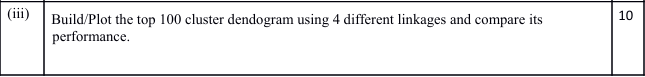

single cophenetic = 0.8101453137405764


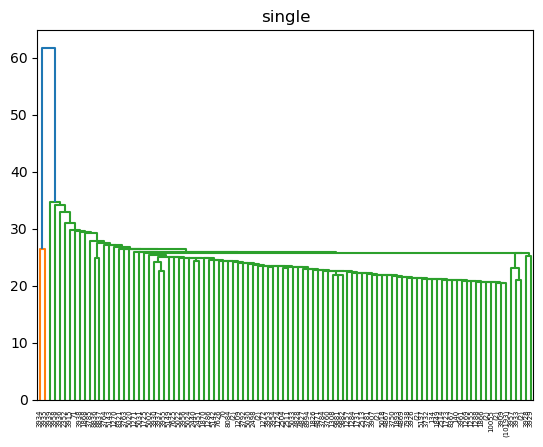

complete cophenetic = 0.7306080742636187


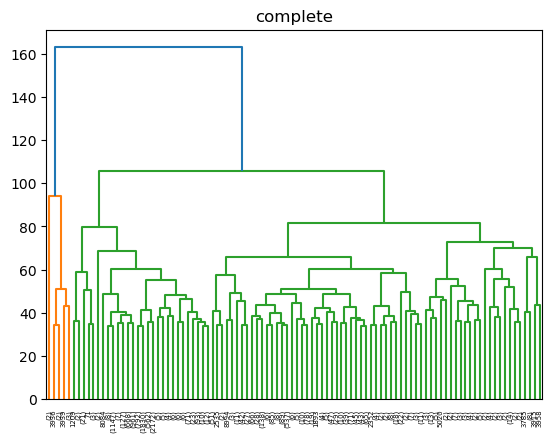

average cophenetic = 0.8591092069107692


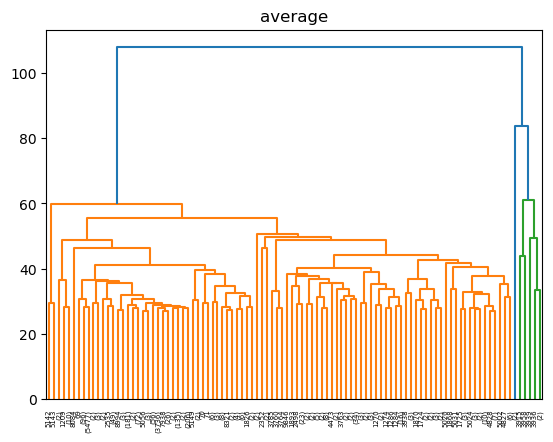

ward cophenetic = 0.6982374327522518


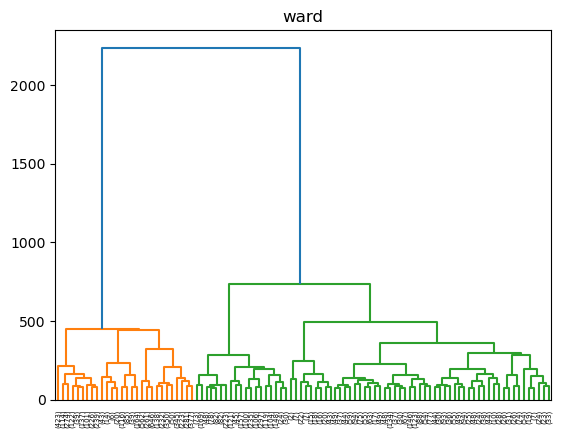

In [24]:
from scipy.cluster.hierarchy import linkage,dendrogram,cophenet
from scipy.spatial.distance import pdist

for method in ['single','complete','average','ward']:
    Z = linkage(X_pca90,method=method)
    c,d = cophenet(Z,pdist(X_pca90))
    print(method,'cophenetic =', c)
    dendrogram(Z,truncate_mode='lastp',p=100)
    plt.title(method)
    plt.show()

Inference = HIghest cophenetic = best dendogram,
Here, Average linkage.
We got compact,balanced clusters

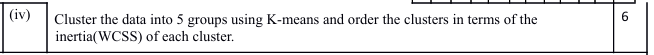

In [25]:
km = KMeans(n_clusters=5,n_init=10,random_state=42)
labels = km.fit_predict(X_pca90)

wcss = {}
for i in range(5):
    points = X_pca90[labels == i]
    wcss[i] = ((points - km.cluster_centers_[i]) ** 2).sum()

print(pd.Series(wcss).sort_values())

2    251431.745342
4    351726.905163
1    406707.441010
0    471972.647042
3    599265.899032
dtype: float64


The first cluster above in rank = 1 is most compact , the last one is most spread out

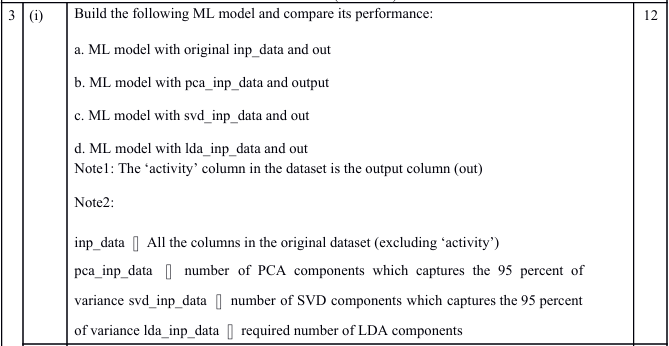

In [26]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

In [27]:
df = pd.read_csv("cluster_data.csv")

X = df.drop("Activity",axis=1)
y = df["Activity"]

X = X.fillna(X.median())

# Split first to avoid leakage
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

# Scale
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [28]:
results = {}

# 1.Original features
model = LogisticRegression(max_iter=1000)
model.fit(X_train,y_train)
results["Original"] = accuracy_score(y_test,model.predict(X_test))

# PCA - 95% features
pca = PCA(n_components=0.95)
A = pca.fit_transform(X_train)
B = pca.transform(X_test)

model = LogisticRegression(max_iter=1000)
model.fit(A,y_train)
results["PCA"] = accuracy_score(y_test,model.predict(B))

print(results)

{'Original': 0.9864077669902913, 'PCA': 0.9684466019417476}


In [29]:
# 3. SVD - approximately 95% variance
svd = TruncatedSVD(n_components=min(X_train.shape[1], X_train.shape[0]-1))
A = svd.fit_transform(X_train)
B = svd.transform(X_test)

n = np.argmax(np.cumsum(svd.explained_variance_ratio_) >= 0.95) + 1
A, B = A[:, :n], B[:, :n]

model = LogisticRegression(max_iter=1000)
model.fit(A, y_train)
results["SVD"] = accuracy_score(y_test, model.predict(B))

In [30]:
# 4. LDA - maximum classes minus one components

lda = LinearDiscriminantAnalysis(n_components=len(np.unique(y_train))-1)
A = lda.fit_transform(X_train,y_train)
B = lda.transform(X_test)

model = LogisticRegression(max_iter=1000)
model.fit(A,y_train)
results["LDA"] = accuracy_score(y_test,model.predict(B))

print(results)

{'Original': 0.9864077669902913, 'PCA': 0.9684466019417476, 'SVD': 0.9679611650485437, 'LDA': 0.9805825242718447}


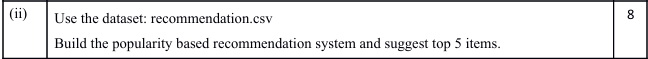

In [31]:
ratings = pd.read_csv("recommendation_mini.csv")
ratings.head()

,UserID,ItemID,Rating,Timestamp
0,905,470,1,889325071
1,697,1518,5,879835275
2,855,1687,5,875638677
3,950,1447,5,877420720
4,806,1170,4,879889337


In [32]:
popular = ratings.groupby("ItemID")["Rating"].count()
print(popular.sort_values(ascending=False).head(5))

ItemID
1650    497
1442    427
1519    427
1600    425
1412    417
Name: Rating, dtype: int64


This ranks products by the number of ratings received. It is a simple popularity measure; it is not personalized.

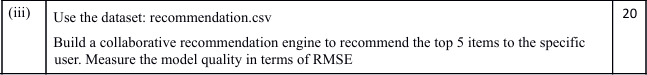

In [38]:
# pip install scikit-surprise

from surprise import Dataset,Reader,SVD,accuracy
from surprise.model_selection import train_test_split

ratings = pd.read_csv("recommendation_mini.csv")

reader = Reader(rating_scale=(1,5))
data = Dataset.load_from_df(
    ratings[["UserID","ItemID","Rating"]],reader
)

# Train/test split and RMSE
train,test = train_test_split(data,test_size=0.25,random_state=42)

model = SVD()
model.fit(train)

pred = model.test(test)
accuracy.rmse(pred)

# Train on full data for recommendations
model.fit(data.build_full_trainset())

user = ratings["UserID"].iloc[0]
rated = set(ratings[ratings.UserID == user]["ItemID"])
items = [i for i in ratings.ItemID.unique() if i not in rated]

predictions = [(i,model.predict(user,i).est) for i in items]
predictions.sort(key=lambda x:x[1],reverse=True)

print(predictions[:5])

RMSE: 0.9468
[(np.int64(1528), np.float64(4.861089452799894)), (np.int64(1650), np.float64(4.831367038933441)), (np.int64(1382), np.float64(4.701885570388052)), (np.int64(1699), np.float64(4.456756955003359)), (np.int64(1387), np.float64(4.44386619801803))]


Remember: Split → train SVD → RMSE → train on full ratings → predict unrated items → top five.